# Redes RBF: de libro de texto a competitivas — notebook reproducible

**Artículo:** *From Textbook to Competitive: A Reproducible Benchmark of Radial Basis
Function Networks and the Role of Adaptive Widths.*
**Autores:** R. A. Vilca-Solorzano · D. M. Yana-Yucra · A. P. Herrera-Urtiaga · M. V. Mamani-Calisaya
(FINESI, Universidad Nacional del Altiplano, Puno, Perú).

Este cuaderno: (1) implementa la **RBF clásica** y la **RBF-Adaptativa (RBF-A)** desde cero;
(2) muestra que en una función suave 1-D la RBF iguala al MLP; (3) revela que en **datos
tabulares reales** la RBF clásica es la peor; y (4) demuestra que **anchuras adaptativas por-centro**
y el **límite kernel (KRR)** cierran la brecha. Semillas fijas → **reproducible**.

> En **Google Colab**: `Entorno de ejecución → Ejecutar todo`. No requiere GPU.

In [1]:
import numpy as np, time, os, urllib.request
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.datasets import load_diabetes

RNG = 42
np.random.seed(RNG)
BLUE, ORANGE, VIOLET, GREEN = "#2a78d6", "#eb6834", "#4a3aa7", "#008300"
plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.25})

## 1. Las dos redes RBF, desde cero

Neurona gaussiana: `φⱼ(x) = exp(−‖x − cⱼ‖² / 2σ²)`; salida lineal por mínimos cuadrados.
La **clásica** usa una anchura global; la **RBF-A** da a cada centro su propia anchura
`σⱼ = s · (distancia media a sus k centros vecinos)`.

In [2]:
def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

class RBFNetwork:
    def __init__(self, n_centers=100, reg=1.0, random_state=RNG):
        self.n_centers, self.reg, self.random_state = n_centers, reg, random_state
    def _phi(self, X):
        P = np.exp(-cdist(X, self.C, "sqeuclidean") / (2 * self.sig ** 2))
        return np.hstack([P, np.ones((len(X), 1))])
    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        m = min(self.n_centers, len(X))
        self.C = KMeans(m, n_init=10, random_state=self.random_state).fit(X).cluster_centers_
        self.sig = cdist(self.C, self.C).max() / np.sqrt(2 * m) + 1e-9
        P = self._phi(X)
        self.w = np.linalg.solve(P.T @ P + self.reg * np.eye(P.shape[1]), P.T @ y)
        return self
    def predict(self, X):
        return self._phi(np.asarray(X, float)) @ self.w

class RBFAdaptive:
    def __init__(self, n_centers=100, k=5, scale=1.0, reg=1e-2, random_state=RNG):
        self.n_centers, self.k, self.scale = n_centers, k, scale
        self.reg, self.random_state = reg, random_state
    def _phi(self, X):
        P = np.exp(-cdist(X, self.C, "sqeuclidean") / (2 * self.sig ** 2))
        return np.hstack([P, np.ones((len(X), 1))])
    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        m = min(self.n_centers, len(X))
        self.C = KMeans(m, n_init=10, random_state=self.random_state).fit(X).cluster_centers_
        ds = np.sort(cdist(self.C, self.C), axis=1)
        self.sig = self.scale * ds[:, 1:min(self.k, m - 1) + 1].mean(axis=1) + 1e-9
        P = self._phi(X)
        self.w = np.linalg.solve(P.T @ P + self.reg * np.eye(P.shape[1]), P.T @ y)
        return self
    def predict(self, X):
        return self._phi(np.asarray(X, float)) @ self.w

## 2. Función 1-D suave: la RBF luce excelente

Aquí la RBF clásica **iguala** a un MLP afinado y entrena sin retropropagación.
**➡️ Demo en vivo:** cambia `noise` o `n_centers` y re-ejecuta.

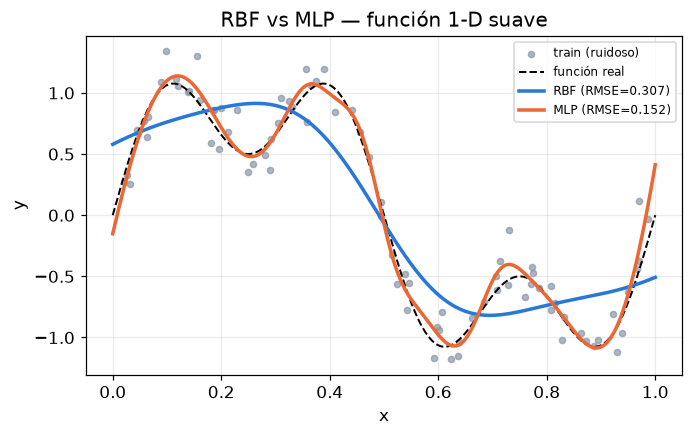

In [3]:
def target(x):
    return np.sin(2*np.pi*x) + 0.5*np.sin(6*np.pi*x)

noise, n_centers = 0.15, 20          # <-- MODIFICA aquí
x = np.sort(np.random.rand(120)); y = target(x) + np.random.normal(0, noise, 120)
xtr, xte, ytr, yte = train_test_split(x, y, test_size=0.3, random_state=RNG)
grid = np.linspace(0, 1, 400)[:, None]

rbf = RBFNetwork(n_centers=n_centers).fit(xtr[:, None], ytr)
mlp = make_pipeline(StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(100,), activation="tanh", solver="lbfgs",
                     max_iter=5000, random_state=RNG)).fit(xtr[:, None], ytr)

plt.figure(figsize=(7, 4))
plt.scatter(xtr, ytr, s=16, color="#8A97A8", alpha=.7, label="train (ruidoso)")
plt.plot(grid, target(grid.ravel()), "k--", lw=1.3, label="función real")
plt.plot(grid, rbf.predict(grid), color=BLUE, lw=2.3,
         label=f"RBF (RMSE={rmse(yte, rbf.predict(xte[:,None])):.3f})")
plt.plot(grid, mlp.predict(grid), color=ORANGE, lw=2.3,
         label=f"MLP (RMSE={rmse(yte, mlp.predict(xte[:,None])):.3f})")
plt.xlabel("x"); plt.ylabel("y"); plt.title("RBF vs MLP — función 1-D suave")
plt.legend(fontsize=8); plt.show()

## 3. Datos tabulares reales

Descargamos (o cargamos localmente) datasets públicos de regresión.

In [4]:
BASE = "https://raw.githubusercontent.com/plotly/datasets/master/"
UCI = "https://archive.ics.uci.edu/ml/machine-learning-databases/"
FILES = {
    "auto-mpg.csv": BASE + "auto-mpg.csv",
    "yacht.data":   UCI + "00243/yacht_hydrodynamics.data",
    "airfoil.dat":  UCI + "00291/airfoil_self_noise.dat",
    "concrete.xls": UCI + "concrete/compressive/Concrete_Data.xls",
    "energy.xlsx":  UCI + "00242/ENB2012_data.xlsx",
}
os.makedirs("data", exist_ok=True)
def fetch(name):
    for p in (f"../data/{name}", f"data/{name}"):
        if os.path.exists(p):
            return p
    dst = f"data/{name}"
    urllib.request.urlretrieve(FILES[name], dst)
    return dst

def load_datasets():
    d = {}
    df = pd.read_csv(fetch("auto-mpg.csv")).apply(pd.to_numeric, errors="coerce").dropna()
    d["auto-mpg"] = (df.drop(columns=["mpg"]).values, df["mpg"].values)
    df = pd.read_csv(fetch("yacht.data"), sep=r"\s+", header=None).dropna()
    d["yacht"] = (df.iloc[:, :-1].values, df.iloc[:, -1].values)
    df = pd.read_csv(fetch("airfoil.dat"), sep=r"\s+", header=None)
    d["airfoil"] = (df.iloc[:, :-1].values, df.iloc[:, -1].values)
    df = pd.read_excel(fetch("concrete.xls"))
    d["concrete"] = (df.iloc[:, :-1].values, df.iloc[:, -1].values)
    df = pd.read_excel(fetch("energy.xlsx")).dropna(axis=1, how="all").dropna()
    d["energy"] = (df.iloc[:, :8].values, df.iloc[:, 8].values)
    d["diabetes"] = load_diabetes(return_X_y=True)
    return d

datasets = load_datasets()
for k, (X, y) in datasets.items():
    print(f"{k:10s} n={len(X):5d}  d={np.asarray(X).shape[1]}")

auto-mpg   n=  396  d=6
yacht      n=  308  d=6
airfoil    n= 1503  d=5
concrete   n= 1030  d=8
energy     n=  768  d=8
diabetes   n=  442  d=10


## 4. Comparación: la RBF clásica falla, la RBF-A y KRR la rescatan

Validación cruzada de 5 pliegues (RMSE, menor = mejor). Observa cómo **RBF-A** y **KRR**
bajan drásticamente frente a la **RBF clásica**, acercándose al Random Forest.

In [5]:
def cv_rmse(factory, X, y, folds=5):
    kf = KFold(folds, shuffle=True, random_state=RNG); out = []
    for tr, te in kf.split(X):
        sc = StandardScaler().fit(X[tr])
        est = factory().fit(sc.transform(X[tr]), y[tr])
        out.append(rmse(y[te], est.predict(sc.transform(X[te]))))
    return np.mean(out)

MODELS = {
    "RBF": lambda: RBFNetwork(n_centers=100, reg=1.0),
    "RBF-A": lambda: RBFAdaptive(n_centers=100, k=5, scale=1.0, reg=1e-2),
    "KRR": lambda: KernelRidge(kernel="rbf", alpha=1e-2),
    "RF": lambda: RandomForestRegressor(n_estimators=150, random_state=RNG),
}
res = {}
for dn, (X, y) in datasets.items():
    X, y = np.asarray(X, float), np.asarray(y, float)
    res[dn] = {m: cv_rmse(f, X, y) for m, f in MODELS.items()}
print(pd.DataFrame(res).T.round(3).to_string())

             RBF   RBF-A     KRR      RF
auto-mpg   3.282   2.876   2.930   2.679
yacht     10.379   3.682   2.646   1.027
airfoil    4.024   3.342   2.701   1.821
concrete  11.689   7.770   5.693   5.086
energy     7.115   2.475   0.855   0.475
diabetes  71.348  56.874  77.152  57.454


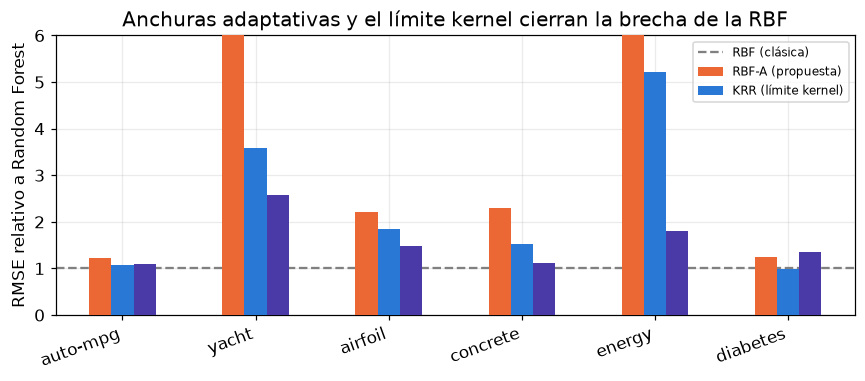

In [6]:
R = pd.DataFrame(res).T
norm = R.div(R["RF"], axis=0)
ax = norm[["RBF", "RBF-A", "KRR"]].plot(kind="bar", figsize=(8, 3.6),
        color=[ORANGE, BLUE, VIOLET], zorder=3)
ax.axhline(1.0, color="grey", ls="--"); ax.set_ylim(0, min(6, norm["RBF"].max()*1.05))
ax.set_ylabel("RMSE relativo a Random Forest"); ax.set_xlabel("")
ax.set_title("Anchuras adaptativas y el límite kernel cierran la brecha de la RBF")
ax.legend(["RBF (clásica)", "RBF-A (propuesta)", "KRR (límite kernel)"], fontsize=8)
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

## 5. Conclusiones

- En **1-D suave** la RBF clásica iguala al MLP (Sec. 2).
- En **tabular real** la RBF clásica es la **peor** de 9 modelos (rango 7.9/9;
  Friedman χ²=32.6, p<10⁻⁴ en el benchmark completo `rbf_benchmark.py`).
- El culpable es la **anchura global**, no la arquitectura (ablación).
- **RBF-A** (anchuras por-centro) reduce el error ~23% (Wilcoxon+Holm p=0.047) y
  supera a MLP/ridge/kNN; **KRR** iguala a SVR.

**Guía honesta:** para exactitud tabular → ensembles de árboles; si se quiere una RBF →
usar anchuras adaptativas o la forma kernel, nunca la clásica de anchura global.

> El benchmark completo (8 datasets × 9 modelos) y la estadística (Friedman + Nemenyi +
> Wilcoxon-Holm) están en `rbf_benchmark.py` y `rbf_stats.py`.